# AI 트렌드

# 1. AI 에이전트

## 1-1. AI 에이전트란?
  
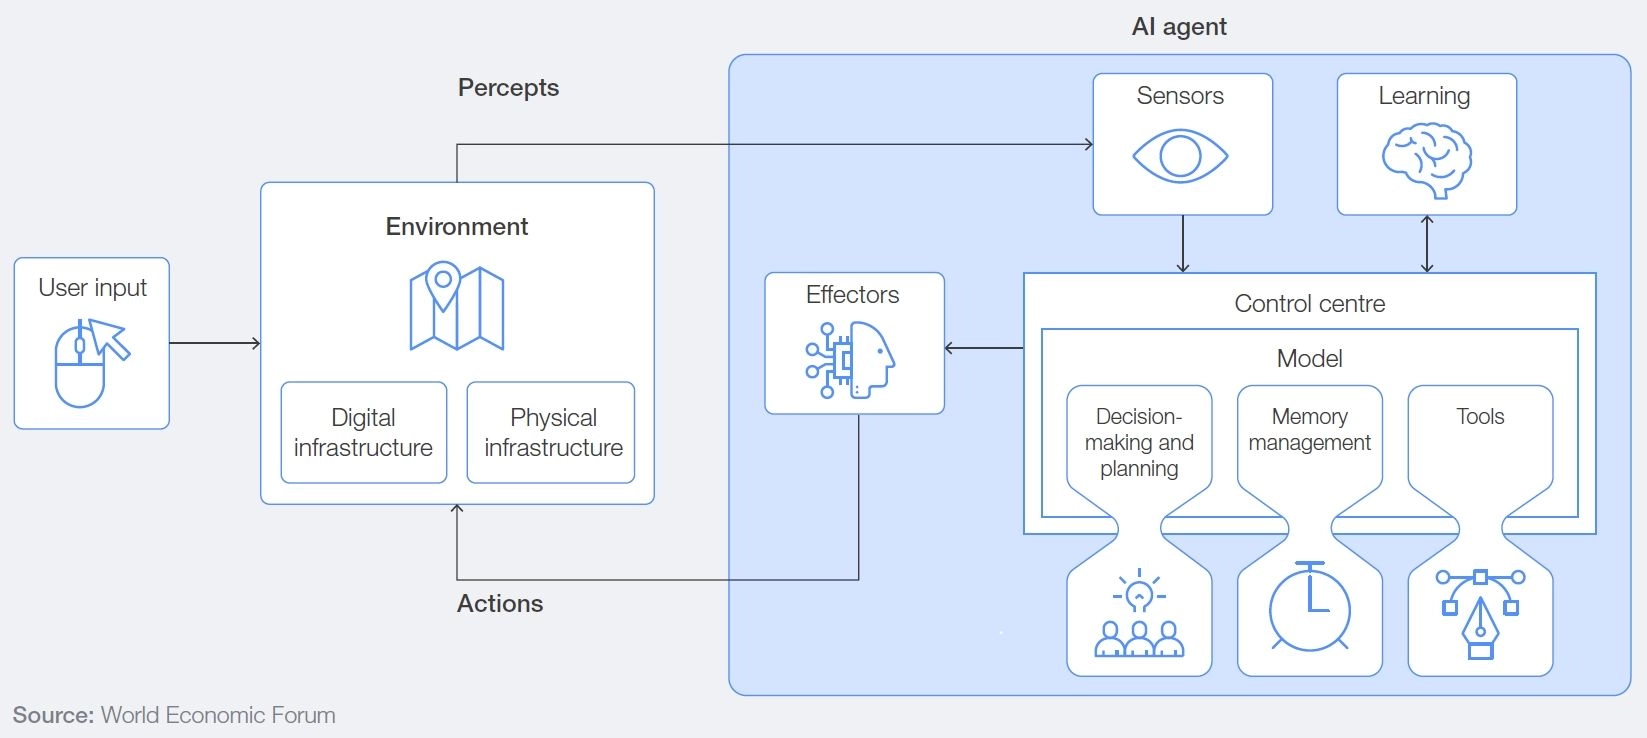  
  
> **AI 에이전트**: 사용자가 정한 목표를 달성하기 위해 AI 모델을 활용해 환경과 상호작용하는 시스템

- 단순히 질문에 답하는 것을 넘어 **추론, 계획, 도구 실행**을 결합해 목표 수행
- 사용자의 지시를 이해하고 필요한 작업을 작은 단계로 나누어 처리
- 외부 환경에서 얻은 결과를 바탕으로 다음 행동을 결정

**생성형 AI와 에이전틱 AI의 차이**

- 생성형 AI
  - 주어진 프롬프트에 대해 답변이나 결과물을 한 번 생성
- 에이전틱 AI
  - 목표가 달성될 때까지 **생각과 행동을 반복**하며 외부 도구 사용

## 1-2. 에이전틱 AI의 작동 방식

### 1. ReAct

> **ReAct**: 추론과 행동을 연결하여 **생각 → 행동 → 관찰 → 다시 생각**하는 과정을 반복하는 방식

**작동 과정**

1. **생각**: 현재 상황을 파악하고 필요한 행동 결정
2. **행동**: 도구 호출을 요청해 정보 조회 또는 작업 수행
3. **관찰**: 실행 결과와 오류를 확인
4. **재계획**: 관찰 결과에 따라 다음 행동을 수정하거나 종료


→ **관찰 결과에 따라 다음 생각과 행동이 달라지는 것**이 핵심

**에이전트 실행 시 필요한 제한**

- 최대 반복 횟수와 비용 한도 설정
- 실패한 도구 호출의 재시도 횟수 제한
- 환불이나 결제 같은 작업의 중복 실행 방지
- 돈이나 데이터가 변경되는 중요한 행동 전 **사람의 승인** 필요

### 2. 에이전트의 상태와 기억

- **단기 상태**: 현재 작업의 진행 단계, 주문번호, 승인 여부 등
- **장기 메모리**: 여러 작업에 걸쳐 유지할 사용자 선호나 업무 정보
- **컨텍스트**: 현재 모델 호출에 실제로 전달한 정보
- 저장된 메모리가 항상 모델에 전달되는 것은 아니므로 필요한 정보를 골라서 컨텍스트에 포함해야 함
- 작업이 중단되었다가 다시 시작되면 저장된 상태와 최신 거래 상태를 함께 확인

**승인 후 재개 과정**

저장된 상태 불러오기 → 최신 주문 및 거래 상태 확인 → 승인 범위 안에서 실행 → 실제 결과 저장 → 완료 상태 갱신

→ 대화에서 실행했다고 말하는 것과 **실제 도구 실행이 완료된 것**은 구분해야 함

### 3. 도구 실행의 주체

- 모델은 어떤 도구를 어떤 값으로 호출할지 **요청을 생성**함
- 요청을 실제로 실행하고 결과를 돌려주는 주체는 **앱**
- 에이전트가 외부 업무를 수행하기 위해서는 모델과 실행 환경의 역할 구분이 필요

## 1-3. 다중 에이전트

> **다중 에이전트**: 여러 에이전트가 역할을 나누고 협력하여 하나의 목표를 수행하는 구조

### 1. 기본 구조

- **오케스트레이터**
  - 전체 요청을 작은 작업으로 분할
  - 적절한 하위 에이전트에 작업 배정
  - 결과를 종합하고 최종 답변 구성
- **서브 에이전트**
  - 검색, 분석, 검토 등 특정 역할을 담당
  - 역할마다 독립적인 작업 공간과 맥락을 사용

### 2. 사용하는 이유

- **검증**: 하나의 에이전트가 계획부터 검토까지 모두 하면 자신의 오류를 놓치기 쉬움 → 별도 검토 에이전트 활용
- **병렬 처리**: 여러 주제를 동시에 조사해 복잡한 작업을 분담
- **맥락 분산**: 한 에이전트가 모든 정보를 기억하지 않아도 되므로 작업별 맥락 관리에 유리

**구조 선택 기준**

- 고정된 순서의 단순 작업 → 정해진 업무 흐름 활용
- 도구 몇 개로 처리할 수 있는 작업 → 단일 에이전트 활용
- 독립적으로 조사한 결과를 모아야 하는 큰 작업 → 다중 에이전트 활용

### 3. 다중 에이전트의 비용과 한계

- 에이전트가 늘어나면 모델 호출과 토큰 사용량도 증가
- 모든 역할에 고성능 모델을 쓰기보다 역할에 맞는 모델을 조합
  - 작업 분배 및 판단 → 고성능 모델
  - 단순 검색 및 정리 → 경량 모델
  - 코드 검증 → 코드 특화 모델
- 여러 에이전트가 토론하며 결과를 검토하는 방식도 활용 가능

### 4. 실제 활용 사례

**Paperclip**

- 여러 에이전트를 직원처럼 조직하고 업무를 관리하는 오픈소스 플랫폼
- 에이전트를 직접 만드는 도구보다는 기존 에이전트들을 운영하는 도구
- 조직도 → 에이전트별 역할과 권한 부여
- 업무 티켓 → 작업 내용과 진행 상태 관리, 중복 작업 방지
- 예산 → 에이전트별 사용 비용 추적 및 제한
- 승인 단계 → 사람이 결과를 검토하고 다음 행동 허용
- 하트비트 → 일정한 시점이나 사건을 계기로 작업 시작

→ 다중 에이전트는 작업 효율을 높일 수 있지만 **복잡성과 실행 비용**도 함께 고려해야 함

# 2. MCP

## 2-1. MCP 이전의 도구 호출  
  
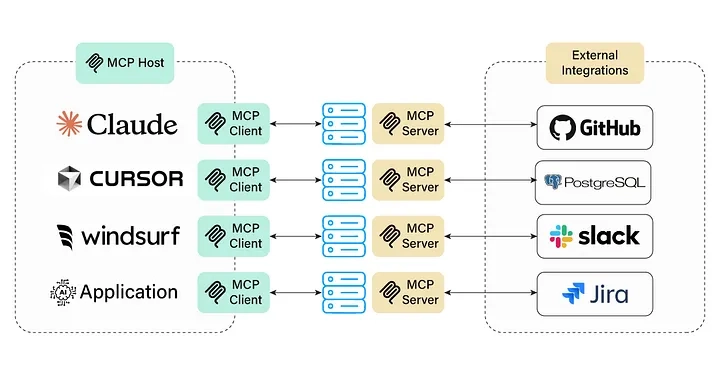  
  

### 1. 함수 호출과 도구 호출

> **도구 호출**: 모델이 사용할 함수의 이름과 입력값을 구조화해 요청하는 기능

- 앱이 질문과 사용할 수 있는 함수 목록을 모델에 전달
- 모델이 도구와 입력값을 선택하여 호출 요청 생성
- 앱이 실제 함수를 실행하고 결과를 모델에 전달
- 모델은 실행 결과를 참고해 최종 답변 작성

→ **도구를 선택하는 기능**과 **도구를 실제 실행하는 기능**은 구분됨

### 2. 개별 연동의 한계

- 여러 AI 앱과 여러 외부 도구를 연결하려면 조합마다 연동 코드가 필요
- AI 앱의 수가 n개, 외부 도구의 수가 m개라면 최대 **n × m개**의 개별 연동 작업 발생
- 앱이나 도구가 추가될 때마다 개발 및 유지보수 부담 증가

**표준을 사용하면**

- 앱은 공통 클라이언트를 구현하고 도구는 공통 서버를 제공
- 개별 조합 대신 **n + m**개의 연결 구조로 단순화 가능

## 2-2. MCP의 등장

> **MCP**: AI 앱과 외부 데이터 및 도구가 공통된 방식으로 통신하도록 하는 개방형 표준 규격

- 서로 다른 앱과 도구를 하나의 규격으로 연결하기 위해 등장
- 2024년 앤트로픽이 공개한 뒤 여러 AI 서비스에서 채택
- 새로운 도구가 추가되어도 해당 서버를 지원하는 여러 앱에서 재사용 가능

**MCP로 표준화되는 내용**

1. **연결 방식**: 앱과 서버가 정해진 규격으로 통신
2. **도구 발견**: 서버가 제공하는 기능 목록을 클라이언트에 전달
3. **도구 호출**: 이름과 입력 형식에 맞게 요청 및 결과 전달
4. **인증**: 원격 서버 연결 시 표준적인 로그인 절차 활용

**도구 호출과 MCP의 관계**

- 도구 호출 → 모델이 **어떤 도구를 사용할지 선택하는 기능**
- MCP → 앱이 외부 도구를 **발견하고 연결하며 실행하는 규격**

MCP 서버에서 도구 목록 받기 → 모델이 호출 요청 생성 → 앱이 MCP를 통해 실행

### 도구 설명의 구성

- **도구 이름**: 호출할 기능을 구분하는 식별자
- **설명**: 모델이 언제 도구를 사용할지 판단하는 근거
- **입력 형식**: 필요한 값의 자료형과 허용 범위 지정
- **필수값**: 요청 시 반드시 전달해야 할 값 지정

→ 설명이 부정확하면 모델이 도구를 잘못 선택할 수 있고, 입력 형식의 제한이 약하면 잘못된 값으로 호출할 위험 증가

## 2-3. MCP의 구조

### 1. 호스트, 클라이언트, 서버

- **호스트**
  - 사용자가 직접 사용하는 AI 앱
  - 모델을 실행하고 도구 사용 여부와 허용 범위 결정
  - 클라이언트를 생성하고 관리
- **클라이언트**
  - 호스트 안에서 서버와 통신을 담당
  - 서버 한 개마다 대응되는 클라이언트를 통해 요청과 결과 전달
- **서버**
  - 외부 시스템의 데이터와 기능을 공통 규격으로 제공
  - 요청에 따라 실제 작업을 수행하고 결과 반환

### 2. 서버가 제공하는 기본 요소

**① 도구**

- 실제 행동을 수행할 수 있는 기능
- 예: 노션 페이지 생성, 깃허브 이슈 등록

**② 리소스**

- 모델이 읽고 참고할 수 있는 데이터
- 예: 파일 내용, 문서, 데이터베이스 구조

**③ 프롬프트**

- 반복해서 사용할 수 있는 요청 양식
- 예: 코드 리뷰나 회의록 요약 템플릿

### 3. 통신 방식

- 정해진 요청 및 응답 형식으로 메시지 교환
- 로컬 서버 → 표준 입출력 방식으로 통신
- 원격 서버 → 인터넷을 통한 통신 방식 사용
- 규격은 지속적으로 개정되므로 연결 방식이나 세부 동작은 버전에 따라 달라질 수 있음

## 2-4. MCP의 작동 흐름

**예시: 노션 회의록 요약**

1. 사용자가 AI 앱에 노션 연결 및 접근 권한 허용
2. 클라이언트가 서버에서 사용 가능한 도구 목록 확인
3. 사용자가 이번 주 회의록 요약 요청
4. 모델이 필요한 검색 도구와 입력값 선택
5. 호스트가 호출 허용 여부 확인 후 서버에 요청 전달
6. 서버가 노션에서 회의록을 검색해 결과 반환
7. 호스트가 결과를 모델에 전달 → 모델이 내용을 요약

→ 모델은 **도구 선택과 답변 생성**, 서버는 **실제 조회와 실행**을 담당

**MCP 서버와 기존 시스템의 관계**

- 서버는 이미 존재하는 업무 시스템이나 외부 서비스에 접근하는 연결 계층
- 예: 주문 조회 요청 → MCP 서버 → 주문 관리 시스템 → 주문 정보 반환
- 요청 형식 오류, 접근 권한 부족, 외부 시스템 응답 실패 등을 각각 구분해 처리해야 함
- 업무 규칙이나 데이터베이스 자체가 사라지는 것은 아니며, 기존 기능을 공통 인터페이스로 제공하는 것

## 2-5. MCP의 한계와 주의점

### 1. 권한과 보안 문제

- MCP는 **연결 방법**을 표준화하지만 어떤 작업을 허용할지는 결정하지 않음
- 서버 접근 권한, 사용자 동의, 위험한 작업의 승인 여부는 호스트에서 관리
- 출처를 알 수 없는 서버 연결은 악성 프로그램에 접근 권한을 주는 것과 유사한 위험

### 2. 프롬프트 주입

> **프롬프트 주입**: 도구를 통해 읽은 외부 데이터에 지시를 숨겨 모델의 행동을 바꾸려는 공격

- **도구 오염**: 도구의 설명에 악의적인 지시를 삽입하는 방식
  - 모델이 기능 설명을 읽고 이를 명령으로 오인할 가능성
- **외부 콘텐츠를 통한 주입**: 검색된 문서나 이슈 내용에 지시를 숨기는 방식
  - 사용자가 원하지 않은 자료 조회나 유출 행동으로 이어질 위험
- 읽기 및 쓰기 권한이 과도하게 넓을수록 피해 범위 확대

### 3. 안전한 사용 원칙

- 공식적이고 검증된 서버만 연결
- 필요한 기능에 한해 **최소 권한** 부여
- 글 게시, 삭제, 결제처럼 되돌리기 어려운 작업은 사람 승인
- 새 서버의 도구 설명과 입력 형식 확인

→ **표준화된 연결이 곧 안전한 연결을 의미하지는 않음**

# 3. 데이터 구조화 — 그래프와 온톨로지

## 3-1. 왜 구조화가 필요한가

### 1. 일반적인 검색 증강 생성의 한계

> **검색 증강 생성**: 관련 문서 조각을 검색해 모델에 전달하고 이를 바탕으로 답변을 생성하는 방식

- 문서를 나누어 벡터로 저장하고 질문과 유사한 조각을 검색
- 각 문서 조각을 독립적으로 비교하므로 **조각 사이의 관계**를 놓치기 쉬움
- 필요한 정보가 질문의 단어와 직접 비슷하지 않으면 검색 결과에서 빠질 수 있음

**상위 검색 결과 수에 따른 문제**

- **상위 결과가 적을 때** → 정답에 필요한 정보를 놓칠 수 있음
- **상위 결과가 많을 때** → 관련 없는 정보까지 포함되어 노이즈와 비용 증가
- 검색 개수만 조절해서는 흩어진 문서 사이의 연결을 충분히 반영하기 어려움

**예시: 특정 영업팀 고객의 불만 조회**

영업팀이 담당하는 제품 확인 → 제품을 구매한 고객 확인 → 해당 고객의 불만 기록 조회

- 불만 기록에 영업팀 이름이 없으면 질문과의 직접적인 유사도는 낮음
- 그러나 **팀 → 제품 → 고객 → 불만**이라는 관계를 따라가면 필요한 정보를 찾을 수 있음

### 2. 검색 성능을 개선하는 방식

**1. 혼합 검색**

- 벡터 기반 의미 검색과 키워드 검색을 함께 활용
- 고유명사나 제품 코드처럼 단어 일치가 중요한 정보 보완
- 질문에 직접 드러나지 않는 관계까지 해결하기는 어려움

**2. 재순위화**

- 많은 문서 후보를 먼저 검색한 뒤 정밀한 모델로 순위를 다시 계산
- 불필요한 결과를 걸러내 검색 품질 향상
- 1차 검색에서 누락된 문서는 복구할 수 없음

**3. 질문 재작성**

- 검색에 유리하도록 질문을 명확히 바꾸거나 여러 질문으로 확장
- 가상 답변 생성, 질문 분해 등을 통해 검색 누락 감소
- 모델 호출이 늘어 비용이 증가하고 원래 의도가 바뀔 수 있음

**4. 반복 검색**

- 검색 결과로 새로운 단서를 얻고 다음 검색을 이어가는 방식
- 문서 간 관계를 단계적으로 찾아갈 수 있음
- 검색 횟수가 증가하고 관계를 매번 새로 추론해야 함

**5. 그래프 기반 검색**

- 문서의 개체와 관계를 미리 추출해 그래프로 저장
- 연결 관계를 따라 필요한 정보를 탐색
- 그래프 구축 및 갱신 비용이 발생

→ 데이터가 여러 시스템에 흩어져 있을수록 **개체와 관계를 함께 구조화하는 방법**이 중요

## 3-2. 그래프 구조와 온톨로지

### 1. 그래프 자료구조

> **그래프**: 데이터를 **노드와 엣지**로 표현하여 대상과 대상 사이의 관계를 나타내는 구조

- **노드**: 사람, 상품, 문서 등 실제 대상이나 개체
- **엣지**: 노드 사이의 관계를 나타내는 연결
- 예: 고객 A → 제품 B 구매 → 영업팀 C가 제품 B 담당
- 일반적인 표가 데이터의 값을 정리한다면 그래프는 **서로 어떻게 연결되는지**를 보여줌

### 2. 온톨로지

> **온톨로지**: 데이터에 등장하는 개체의 종류와 속성, 관계를 정의하여 의미 있는 구조로 표현하는 방법

- 여러 데이터 소스에 흩어진 정보를 같은 개념과 관계로 연결
- 단순한 문서 검색을 넘어 업무 대상 사이의 맥락 파악 가능
- 팔란티어 온톨로지는 그래프 구조를 기업 전반에 적용하고 **행동과 권한**까지 연결한 형태

### 3. 팔란티어 온톨로지의 구성요소

**1. 객체 타입과 객체**

- **객체 타입**: 어떤 종류의 데이터인지 정의한 틀
  - 예: 고객이라는 대상이 이름, 등급, 생성일자를 가지도록 정의
- **객체**: 정의된 타입에 속하는 실제 개별 대상
  - 예: 고객 A, 제품 B
- **객체 세트**: 조건에 따라 묶인 여러 객체의 집합
  - 예: 우수 고객 전체

**2. 속성과 속성값**

- **속성**: 객체의 특징을 나타내는 항목
- **속성값**: 각 객체가 실제로 가지는 값
- **공유 속성**: 여러 객체 타입에서 공통으로 사용하는 속성

**3. 링크 타입과 링크**

- **링크 타입**: 두 객체 사이의 관계를 정의한 틀
- **링크**: 실제 개별 객체 사이에 존재하는 관계

**4. 액션 타입**

- 데이터를 조회하는 것을 넘어 실제 변경이나 업무 행동을 정의
- 에이전트가 도구를 호출하여 실행할 수 있는 업무 동작과 연결

**5. 역할과 권한**

- 부서나 직무에 따라 접근할 수 있는 데이터 및 행동 범위 제한
- AI 에이전트에도 사람과 같은 방식으로 권한 부여 가능
- 허용된 객체와 작업 범위 안에서만 조회와 실행 수행

→ 일반 그래프가 **관계 표현**에 초점을 둔다면, 팔란티어 온톨로지는 **기업 업무의 의미와 실행 및 권한**까지 함께 다룸

## 3-3. 실전 활용 방식

### 1. 그래프 기반 검색 증강 생성

- 문서에서 개체와 개체 간 관계를 추출하여 지식 그래프 생성
- 질문에 관련된 개체를 찾고 그래프의 연결을 따라 정보 탐색
- **로컬 검색**: 특정 개체와 주변 관계를 중심으로 찾는 방식
- **글로벌 검색**: 데이터 전체의 주요 주제나 공통된 흐름을 파악하는 방식

**일반 검색 방식과의 차이**

- 일반 검색 → 질문과 유사한 문서 조각을 개별적으로 선택
- 그래프 기반 검색 → **관계망을 따라 연결된 정보**까지 함께 활용
- 장점: 여러 단계를 거쳐야 알 수 있는 관계 파악에 유리
- 단점: 그래프 생성 및 유지에 추가 비용 필요

### 2. GraphRAG와 LightRAG

**GraphRAG**

- 문서에서 개체와 관계를 추출해 그래프 구성
- 그래프를 주제별로 묶고 요약 정보를 만들어 검색에 활용
- 특정 개체의 관계 탐색과 전체 주제 요약에 활용
- 그래프 및 커뮤니티 요약 생성 과정에서 모델 호출 비용 발생

**LightRAG**

- 그래프 기반 검색의 장점을 유지하면서 사전 구축 비용을 줄이려는 방식
- 개체 중심의 구체적인 검색어와 주제 중심의 추상적인 검색어를 함께 활용
- 커뮤니티 요약을 미리 생성하는 단계를 생략해 비용을 줄일 수 있음

**LightRAG의 검색 방식**

- 기본 검색 → 일반적인 문서 조각 유사도 검색
- 로컬 검색 → 구체적인 개체와 관계 중심
- 글로벌 검색 → 넓은 주제와 개념 중심
- 혼합 검색 → 로컬 검색과 글로벌 검색 결합

→ 관계를 활용한다는 공통점이 있지만 **사전 준비 방식과 계산 비용**에서 차이

### 3. 기타 활용 사례

**Graphify**

- 폴더 안의 코드와 문서를 분석해 파일 및 개념 사이의 연결을 그래프로 정리
- 기존에 존재하는 자료를 관계망으로 만드는 데 활용

**팔란티어 온톨로지의 제조업 적용**

- 공장, 생산 지시서, 기계, 창고, 고객 및 운송 정보를 연결
- 납품 지연 발생 시 공장 → 작업 지시서 → 물류 → 고객 순서로 원인 추적
- 시스템별로 따로 자료를 확인하지 않아도 연결된 정보를 바탕으로 분석 가능

→ **그래프는 데이터를 관계로 연결하고, 온톨로지는 관계에 의미와 업무 행동을 부여**

# 4. 설명 가능한 인공지능

## 4-1. 블랙박스가 왜 문제인가

> **설명 가능한 인공지능**: AI 모델이 어떤 근거와 과정으로 판단했는지 이해하고 검증하기 위한 방법

- 딥러닝 모델은 많은 파라미터가 복잡하게 연결되어 내부 판단 과정을 이해하기 어려움
- 입력과 출력만으로는 모델이 **올바른 근거**를 학습했는지 알기 어려움
- 예: 피부 병변 사진의 반창고를 질병의 특징으로 잘못 학습하는 경우
- 실제 판단 근거가 잘못되어도 표면적인 예측 정확도만으로 문제를 발견하기 어려움

**설명 가능성이 필요한 이유**

- **책임성**: 의료, 금융, 채용 등 중요한 결정의 이유 확인
- **오류 탐지**: 모델이 잘못된 상관관계나 편향을 학습했는지 파악
- **신뢰 확보**: 사용자와 운영자가 모델의 판단을 검토할 수 있도록 지원
- **안전한 실행**: 에이전트의 판단이 실제 업무 행동으로 이어질 때 근거 확인 필요

## 4-2. 기존 해결 시도

### 1. 회귀분석

- 입력 변수에 곱해지는 계수를 직접 확인할 수 있는 설명 가능한 모델
- 각 변수가 예측 결과에 어느 정도 영향을 주는지 비교적 쉽게 해석
- 장점: 구조가 단순하고 판단 근거가 명확함
- 단점: 이미지, 텍스트 등 복잡한 비선형 관계를 표현하는 데 한계

### 2. SHAP

> **SHAP**: 게임 이론의 기여도 개념을 활용해 각 입력 특성이 예측값에 미친 영향을 계산하는 방법

**작동 과정**

1. 전체 데이터의 평균적인 예측값을 기준으로 설정
2. 여러 입력 특성의 포함 및 제외 조합 고려
3. 각 특성이 들어왔을 때 예측값이 얼마나 달라지는지 계산
4. 여러 조합의 기여도를 평균하여 최종 기여도 산출

- **양의 기여도** → 예측값을 높이는 방향으로 영향
- **음의 기여도** → 예측값을 낮추는 방향으로 영향

**장점**

- 각 특성의 영향력을 수치화하여 설명 가능
- 개별 예측과 전체적인 특성 중요도를 함께 분석 가능
- 기여도 합과 예측값 사이에 수학적인 관계가 있음

**단점**

- 특성의 조합이 많아지면 계산 비용 증가
- 복잡한 모델에서는 근사 계산이 필요할 수 있음
- 계산된 기여도가 모델 내부의 실제 인과적 연산을 직접 보여주는 것은 아님

### 3. LIME

> **LIME**: 특정 예측값 주변의 데이터를 변형하고 간단한 모델로 근사하여 그 예측을 설명하는 방법

**작동 과정**

1. 설명하고 싶은 입력 데이터 선택
2. 주변의 비슷한 데이터를 여러 개 생성
3. 기존 복잡한 모델로 생성된 데이터의 예측값 계산
4. 주변 데이터에 잘 맞는 간단한 모델 학습
5. 간단한 모델의 계수 등을 이용해 중요한 특성 해석

**장점**

- 기존 모델의 종류와 관계없이 활용 가능
- 한 개의 예측에 영향을 준 주요 요소를 직관적으로 파악
- 복잡한 모델을 직접 수정하지 않아도 설명 생성 가능

**단점**

- 샘플링한 위치에 따라 설명 결과가 달라질 수 있음
- 개별 사례에 대한 설명이므로 모델 전체의 일관된 동작을 보장하지 않음

### 4. 언어 모델과 검색을 활용한 설명

- 모델의 입력과 출력, 참고 자료를 언어 모델에 제공해 자연어 설명 생성
- 장점: 사용자가 이해하기 쉬운 설명을 만들 수 있음
- 단점: 만들어진 설명이 원래 모델의 실제 판단 과정과 일치한다는 보장 없음

→ 기존의 사후 설명 방식은 **결과에 영향을 준 것으로 보이는 요소**를 알려주지만, 내부 연산 자체를 보여주기는 어려움

## 4-3. 기계적 해석 가능성

> **기계적 해석 가능성**: 모델의 가중치, 뉴런, 어텐션 헤드 등을 직접 분석하여 특정 기능이 내부에서 어떻게 구현되는지 이해하는 연구

- 일반적인 설명 방법 → 입력과 출력의 관계를 모델 바깥에서 추정
- 기계적 해석 가능성 → 모델 내부의 연산 구조와 정보 전달 경로를 직접 분석
- 개별 뉴런뿐 아니라 여러 요소가 연결된 **회로 수준**까지 조사

### 활성값 패칭

> **활성값 패칭**: 서로 다른 입력을 처리할 때 특정 내부 위치의 활성값을 교체하고 출력의 변화를 관찰하는 실험 방법

**작동 과정**

1. 서로 다른 답을 내는 기준 입력과 비교 입력 준비
   - 예: 프랑스의 수도 질문 → 파리 / 독일의 수도 질문 → 베를린
2. 비교 입력을 처리하는 동안 특정 위치의 활성값을 기준 입력의 값으로 교체
3. 최종 답변이 어떻게 달라지는지 관찰

- 출력이 파리로 바뀌면 → 교체한 위치가 국가 정보를 전달하는 중요한 경로일 가능성
- 출력이 바뀌지 않으면 → 해당 위치 하나만으로는 결과가 바뀌지 않음

→ 특정 내부 요소가 **답변 생성에 실제로 영향을 주는지** 실험적으로 확인

## 4-4. 기계적 해석 가능성의 핵심 개념

### 1. 특징

- 모델이 입력에서 인식한 단어나 말투, 상황 등의 개념
- 한 개의 뉴런으로 표현되거나 여러 뉴런의 활성값 조합으로 표현될 수 있음
- 해당 개념이 등장하면 관련 활성값이 커짐
- 현실의 모델에서는 **뉴런 하나와 개념 하나가 정확히 대응하지 않는 경우**가 많음

### 2. 회로

> 여러 뉴런과 어텐션 헤드가 연결되어 특정 기능을 수행하는 내부 구조

- 복잡한 판단을 여러 단계로 나누어 처리
- 예: 문장의 주어 파악 → 동사 파악 → 정보 결합 → 특정 단어의 위치 예측
- 회로를 파악하면 모델 내부에서 기능이 구현된 위치와 정보 전달 과정을 분석 가능

### 3. 중첩

> **중첩**: 제한된 뉴런과 표현 공간 안에 여러 개념을 겹쳐서 표현하는 현상

- 하나의 개념이 하나의 뉴런에만 저장되는 것이 아님
- 여러 개념을 서로 다른 방향의 벡터로 표현하면서 일부가 겹침
- 겹치는 개념 사이에는 **간섭**이 발생할 수 있음
- 서로 다른 개념이 동시에 활성화되는 경우가 드물면 겹쳐 표현하는 것이 효율적
- 이 때문에 한 뉴런을 관찰해도 어떤 개념을 나타내는지 정확히 구분하기 어려움

**희소 오토인코더**

- 여러 뉴런에 섞여 표현된 특징을 분리하여 해석하려는 방법
- 모델 내부 활성값을 분석해 비교적 독립적인 특징을 찾아냄
- 중첩된 표현을 나누어 개별 개념의 작동을 연구하는 데 활용

## 4-5. 실제 연구 사례

### 1. 유도 헤드

- 앞에 나온 토큰 패턴을 찾아 다음에 올 토큰을 예측하는 어텐션 헤드 연구
- 하나의 헤드가 앞에서 비슷한 패턴을 찾고, 다른 헤드가 그 위치 다음 토큰을 복사하는 구조
- 언어 모델의 문맥 내 학습 능력을 내부 회로 관점에서 이해하려는 사례

### 2. 희소 오토인코더를 통한 특징 분리

- 모델 내부에 중첩된 개념을 분리해 의미 있는 특징 탐색
- 특정 개념과 관련된 특징을 강하게 활성화할 때 모델의 출력이 달라지는 실험 수행

### 3. 이미지 분류 회로 분석

- 선과 곡선 같은 기초 특징 → 눈, 코 등 부분 형태 → 얼굴 인식
- 학습된 모델 내부에서 작은 특징들이 결합해 복잡한 개념을 만드는 경로 분석

### 4. 모델의 지식 편집

- 특정 사실과 연결된 모델 내부 위치를 탐색
- 해당 위치의 가중치를 변경하여 모델이 기억한 사실을 바꾸는 실험
- 검색이나 전체 재학습 없이 일부 내부 표현을 직접 수정하는 방식

## 4-6. 설명 가능성이 중요한 이유

- AI가 단순 답변 생성을 넘어 **실제 의사결정과 업무 실행**에 활용되는 범위 확대
- 테스트 정확도만으로는 모델이 안전하게 판단하는지 확인하기 어려움
- 내부 회로와 특징을 분석해 잘못된 판단 경로를 발견할 가능성
- 다만 대규모 모델의 전체 작동을 해석하는 연구는 아직 초기 단계

→ 설명 가능한 인공지능의 관심이 **결과를 그럴듯하게 설명하는 것**에서 **모델 내부의 작동 원리를 직접 이해하는 것**으로 확대되고 있음